# Phase 6.4 - Clustering de Contexto Hibrido Balanceado

Objetivo: mantener buena separacion de retornos entre "palabras/regimenes" sin perder demasiada cobertura.

Estrategia:
1. Partir de `v6.2` (base robusta) y `v6.3` (pareja hibrida v62+fused).
2. Construir token par `pair_token = w_v62 + w_fused`.
3. Colapsar solo los `top_n` pares mas frecuentes (train+val), el resto a `other`.
4. Elegir `top_n` por walk-forward para balancear `eta2`, `coverage` y cantidad de grupos activos.

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path('.')

# Ejecuta pipeline v6.4 balanceado
import importlib.util
script_path = ROOT / 'phases/phase06_context_regimes/run_v6_4_hybrid_balanced.py'
spec = importlib.util.spec_from_file_location('run_v6_4_hybrid_balanced', script_path)
mod = importlib.util.module_from_spec(spec)
spec.loader.exec_module(mod)
mod.main()

OUT_DIR = ROOT / 'phases/phase06_context_regimes/output_context_words_GBPUSD_v6_4_hybrid_balanced_from_v5_1'
SUMMARY_JSON = OUT_DIR / 'GBPUSD_context_words_hybrid_balanced_summary_v6_4.json'
METRICS_CSV = OUT_DIR / 'GBPUSD_context_words_hybrid_balanced_metrics_v6_4.csv'
SELECTION_CSV = OUT_DIR / 'GBPUSD_context_words_hybrid_balanced_selection_v6_4.csv'
PROFILE_CSV = OUT_DIR / 'GBPUSD_context_words_hybrid_balanced_profile_v6_4.csv'
TRANS_CSV = OUT_DIR / 'GBPUSD_context_words_hybrid_balanced_transition_matrix_v6_4.csv'
LABELS_PQ = OUT_DIR / 'GBPUSD_context_words_hybrid_balanced_v6_4.parquet'

summary = json.loads(SUMMARY_JSON.read_text())
metrics = pd.read_csv(METRICS_CSV)
selection = pd.read_csv(SELECTION_CSV)
profile = pd.read_csv(PROFILE_CSV)
trans = pd.read_csv(TRANS_CSV, index_col=0)
labels = pd.read_parquet(LABELS_PQ)

print('summary ->', SUMMARY_JSON)
print('metrics ->', METRICS_CSV)
print('selection ->', SELECTION_CSV)
print('labels ->', LABELS_PQ)

Saved:
 - ./phases/phase06_context_regimes/output_context_words_GBPUSD_v6_4_hybrid_balanced_from_v5_1/GBPUSD_context_words_hybrid_balanced_v6_4.parquet
 - ./phases/phase06_context_regimes/output_context_words_GBPUSD_v6_4_hybrid_balanced_from_v5_1/GBPUSD_context_words_hybrid_balanced_metrics_v6_4.csv
 - ./phases/phase06_context_regimes/output_context_words_GBPUSD_v6_4_hybrid_balanced_from_v5_1/GBPUSD_context_words_hybrid_balanced_summary_v6_4.json

Metrics:
                      model  n_test_rows  n_groups_active  coverage_active_groups  kw_pvalue  anova_pvalue     eta2
           phase6_v6_2_base          241                7                0.892116   0.001661      0.001609 0.096539
       phase6_v6_3_pair_raw          241                4                0.369295   0.003405      0.008747 0.127232
phase6_v6_4_hybrid_balanced          241                3                0.605809   0.005715      0.003863 0.074769
summary -> ./phases/phase06_context_regimes/output_context_words_GBPUSD_v6_

In [2]:
pd.set_option('display.max_columns', 260)
pd.set_option('display.width', 240)

print('Resumen:')
print('best_top_n =', summary['best_top_n'])
print('selection_mode =', summary['selection_mode'])
print('split_counts =', summary['split_counts'])
print('\nTabla de metricas (test):')
display(metrics)

Resumen:
best_top_n = 15
selection_mode = feasible
split_counts = {'train': 1100, 'val': 241, 'test': 241}

Tabla de metricas (test):


,model,n_test_rows,n_groups_active,coverage_active_groups,kw_pvalue,anova_pvalue,eta2
0,phase6_v6_2_base,241,7,0.892116,0.001661,0.001609,0.096539
1,phase6_v6_3_pair_raw,241,4,0.369295,0.003405,0.008747,0.127232
2,phase6_v6_4_hybrid_balanced,241,3,0.605809,0.005715,0.003863,0.074769


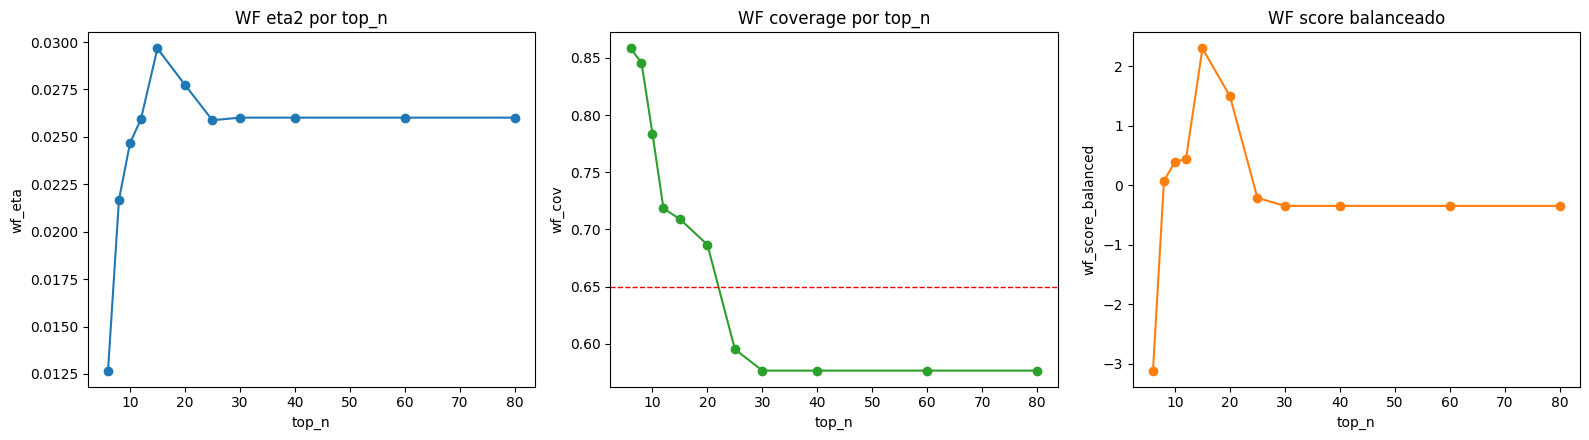

,top_n,wf_eta,wf_cov,wf_n_groups,z_eta,z_cov,z_ng,wf_score_balanced,feasible
0,15,0.029661,0.708955,3.00,1.158546,0.255193,1.076055,2.299330,True
1,20,0.027743,0.686567,3.00,0.705477,0.042890,1.076055,1.498037,True
2,12,0.025945,0.718284,2.25,0.280944,0.343653,-0.538028,0.439867,False
3,10,0.024661,0.783582,2.00,-0.022361,0.962872,-1.076055,0.395775,False
4,8,0.021696,0.845771,2.00,-0.722546,1.552604,-1.076055,0.075266,False
5,25,0.025876,0.595149,2.75,0.264633,-0.824017,0.538028,-0.210980,False
6,30,0.026013,0.576493,2.75,0.296914,-1.000936,0.538028,-0.345934,False
7,60,0.026013,0.576493,2.75,0.296914,-1.000936,0.538028,-0.345934,False
8,40,0.026013,0.576493,2.75,0.296914,-1.000936,0.538028,-0.345934,False
9,80,0.026013,0.576493,2.75,0.296914,-1.000936,0.538028,-0.345934,False


In [3]:
# Curva de seleccion walk-forward por top_n
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

sel = selection.sort_values('top_n').copy()

axes[0].plot(sel['top_n'], sel['wf_eta'], marker='o')
axes[0].set_title('WF eta2 por top_n')
axes[0].set_xlabel('top_n')
axes[0].set_ylabel('wf_eta')

axes[1].plot(sel['top_n'], sel['wf_cov'], marker='o', color='tab:green')
axes[1].axhline(0.65, linestyle='--', color='red', linewidth=1)
axes[1].set_title('WF coverage por top_n')
axes[1].set_xlabel('top_n')
axes[1].set_ylabel('wf_cov')

axes[2].plot(sel['top_n'], sel['wf_score_balanced'], marker='o', color='tab:orange')
axes[2].set_title('WF score balanceado')
axes[2].set_xlabel('top_n')
axes[2].set_ylabel('wf_score_balanced')

plt.tight_layout()
plt.show()

display(selection.sort_values('wf_score_balanced', ascending=False).reset_index(drop=True))

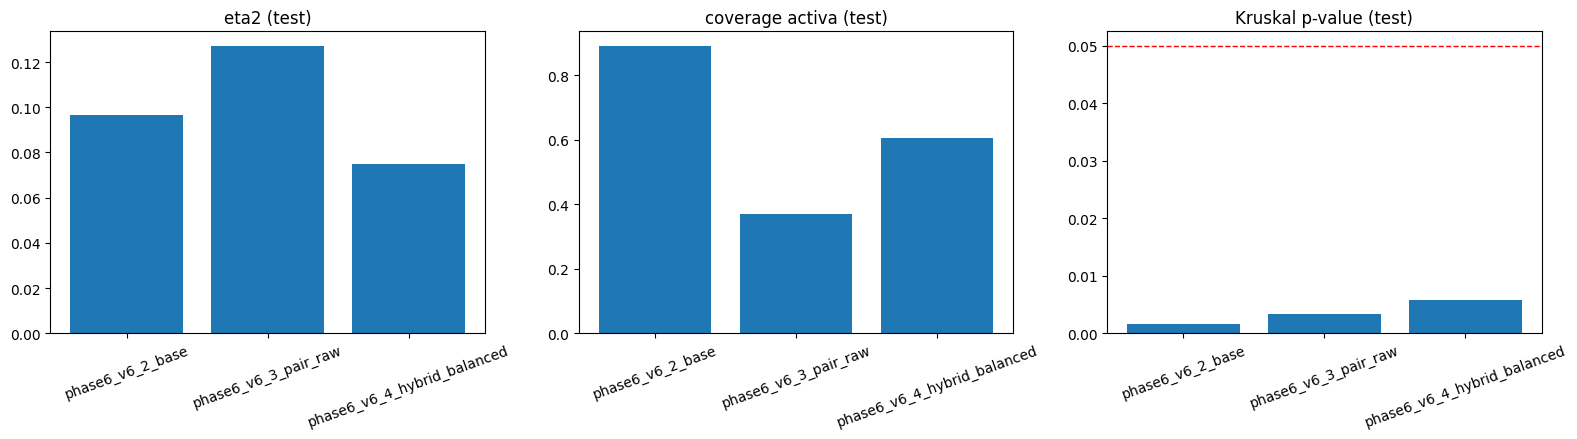

In [4]:
# Comparativo final entre modelos
m = metrics.copy()

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
axes[0].bar(m['model'], m['eta2'])
axes[0].set_title('eta2 (test)')
axes[0].tick_params(axis='x', rotation=20)

axes[1].bar(m['model'], m['coverage_active_groups'])
axes[1].set_title('coverage activa (test)')
axes[1].tick_params(axis='x', rotation=20)

axes[2].bar(m['model'], m['kw_pvalue'])
axes[2].axhline(0.05, linestyle='--', color='red', linewidth=1)
axes[2].set_title('Kruskal p-value (test)')
axes[2].tick_params(axis='x', rotation=20)

plt.tight_layout()
plt.show()

In [5]:
print('Top perfiles (v6.4 balanced):')
display(profile.head(15))

print('Transicion (submatriz 12x12):')
display(trans.iloc[:12, :12])

print('Muestra de etiquetas finales:')
display(labels.head(10))

Top perfiles (v6.4 balanced):


,word_hybrid_balanced_token,n,mean_ret,median_ret,std_ret,t_like
0,other,102,-17.324476,-18.750429,97.716388,-0.177293
1,w03_wf01,23,76.769590,74.599981,125.522855,0.611599
2,w02_wf01,21,-23.009550,-37.900209,207.709570,-0.110778
3,w00_wf04,19,-7.357911,9.399652,87.577319,-0.084016
4,w10_wf01,18,11.788872,20.200014,83.615067,0.140990
5,w02_wf03,18,-5.866753,-10.100007,96.938340,-0.060520
6,w07_wf03,16,-11.937618,-50.849915,123.103623,-0.096972
7,w07_wf01,15,-64.480225,-56.799650,105.294729,-0.612378
8,w11_wf01,8,11.200309,-12.849569,119.707690,0.093564
9,w00_wf03,1,21.799803,21.799803,NaN,NaN


Transicion (submatriz 12x12):


,other,w00_wf01,w00_wf03,w00_wf04,w02_wf01,w02_wf03,w03_wf01,w05_wf01,w07_wf01,w07_wf03,w09_wf01,w10_wf01
word_hybrid_balanced_token,,,,,,,,,,,,
other,0.945087,0.000000,0.008671,0.005780,0.000000,0.002890,0.002890,0.002890,0.002890,0.008671,0.000000,0.008671
w00_wf01,0.013699,0.931507,0.013699,0.027397,0.000000,0.000000,0.013699,0.000000,0.000000,0.000000,0.000000,0.000000
w00_wf03,0.012048,0.024096,0.915663,0.000000,0.000000,0.036145,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
w00_wf04,0.050000,0.000000,0.033333,0.916667,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
w02_wf01,0.017544,0.017544,0.000000,0.000000,0.789474,0.070175,0.070175,0.000000,0.000000,0.000000,0.017544,0.000000
w02_wf03,0.008264,0.000000,0.000000,0.000000,0.057851,0.909091,0.016529,0.000000,0.000000,0.000000,0.008264,0.000000
w03_wf01,0.018519,0.000000,0.000000,0.000000,0.018519,0.009259,0.888889,0.000000,0.037037,0.018519,0.000000,0.000000
w05_wf01,0.071429,0.000000,0.023810,0.023810,0.000000,0.000000,0.000000,0.880952,0.000000,0.000000,0.000000,0.000000
w07_wf01,0.012195,0.012195,0.000000,0.000000,0.006098,0.000000,0.018293,0.000000,0.902439,0.048780,0.000000,0.000000


Muestra de etiquetas finales:


,base_window_id_end,start_ts,end_ts,split,ret_fwd_24h_pips,word_v62_id,word_v62_token,word_fused_id,word_fused_token,pair_token,word_hybrid_balanced_id,word_hybrid_balanced_token
0,23,2000-05-31 10:00:00,2001-01-24 04:00:00,train,-106.999874,5,w05,1,wf01,w05_wf01,7,w05_wf01
1,24,2000-06-02 02:00:00,2001-01-25 21:00:00,train,0.000000,0,w00,3,wf03,w00_wf03,2,w00_wf03
2,25,2000-06-08 02:00:00,2001-02-02 02:00:00,train,-97.999573,0,w00,3,wf03,w00_wf03,2,w00_wf03
3,26,2000-06-12 20:00:00,2001-02-08 02:00:00,train,-81.000328,0,w00,3,wf03,w00_wf03,2,w00_wf03
4,27,2000-06-14 22:00:00,2001-02-15 00:00:00,train,-58.000088,0,w00,3,wf03,w00_wf03,2,w00_wf03
5,28,2000-06-28 22:00:00,2001-02-19 23:00:00,train,-19.000769,0,w00,3,wf03,w00_wf03,2,w00_wf03
6,29,2000-07-12 05:00:00,2001-02-21 05:00:00,train,-16.000271,0,w00,3,wf03,w00_wf03,2,w00_wf03
7,30,2000-07-20 02:00:00,2001-03-09 00:00:00,train,-44.000149,0,w00,3,wf03,w00_wf03,2,w00_wf03
8,31,2000-07-28 02:00:00,2001-03-12 21:00:00,train,-140.999556,0,w00,3,wf03,w00_wf03,2,w00_wf03
9,32,2000-08-03 00:00:00,2001-03-20 22:00:00,train,-58.999062,0,w00,3,wf03,w00_wf03,2,w00_wf03
